<a href="https://colab.research.google.com/github/anvisingla09/UCS532-CV-PROJECT/blob/main/Image_Text_Retreival.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q datasets pandas numpy scikit-learn matplotlib pillow

In [6]:
!git clone https://github.com/anvisingla09/UCS532-CV-PROJECT.git

Cloning into 'UCS532-CV-PROJECT'...
remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 4 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (4/4), done.


In [7]:
%cd UCS532-CV-PROJECT

/content/UCS532-CV-PROJECT


In [8]:
import os

folders = [
    "src",
    "configs",
    "data",
    "results/tables",
    "results/figures",
    "results/logs",
    "report"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

for folder in folders:
    print(folder)

Project folders created successfully!
src
configs
data
results/tables
results/figures
results/logs
report


In [9]:
%%writefile src/load_data.py

import random
import numpy as np
import pandas as pd
from datasets import load_dataset

SEED = 42

def load_bodhisetu():

    random.seed(SEED)
    np.random.seed(SEED)

    print("Loading Bodhisetu enriched dataset...")

    dataset = load_dataset(
        "51Hypers/Bodhisetu",
        "enriched",
        split="train"
    )

    df = dataset.to_pandas()

    print("Dataset loaded successfully!")
    print("Total records:", len(df))

    print("\nMedia distribution:")
    print(df["media_type"].value_counts())

    images_df = df[
        df["media_type"].astype(str).str.upper() == "IMAGE"
    ].copy()

    print("\nTotal image records:", len(images_df))

    return df, images_df


if __name__ == "__main__":

    df, images_df = load_bodhisetu()

    images_df.to_csv(
        "data/dataset_manifest.csv",
        index=False
    )

    print("\nImage manifest saved successfully!")

Writing src/load_data.py


In [10]:
!python src/load_data.py

Loading Bodhisetu enriched dataset...
Dataset loaded successfully!
Total records: 5753

Media distribution:
media_type
IMAGE    4461
VIDEO    1292
Name: count, dtype: int64

Total image records: 4461

Image manifest saved successfully!


In [2]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import os
import random

# Fix random seeds
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Loading Bodhisetu enriched dataset...")

ds = load_dataset(
    "51Hypers/Bodhisetu",
    "enriched",
    split="train"
)

print("Dataset loaded successfully!")
print(ds)

Loading Bodhisetu enriched dataset...


README.md:   0%|          | 0.00/5.00k [00:00<?, ?B/s]

enriched/data.parquet: reconstructing file:   0%|          |  0.00B / 1.59MB            

enriched/data.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Dataset loaded successfully!
Dataset({
    features: ['entity_uid', 'name', 'language', 'taluk', 'state', 'domain', 'subdomain', 'location_text', 'gps_lat', 'gps_lng', 'keywords_tags', 'significance_status', 'frequency_seasonality', 'time_period_era', 'colloquial_name', 'resource_id', 'media_path', 'media_type', 'description', 'transcript', 'transcript_language'],
    num_rows: 5753
})


In [3]:
df = ds.to_pandas()

print("Dataset shape:", df.shape)

print("\nAll columns:")
print(df.columns.tolist())

print("\nMedia type distribution:")
print(df["media_type"].value_counts())

print("\nHeritage domains:")
print(df["domain"].value_counts())

print("\nFirst five records:")
display(df.head())

Dataset shape: (5753, 21)

All columns:
['entity_uid', 'name', 'language', 'taluk', 'state', 'domain', 'subdomain', 'location_text', 'gps_lat', 'gps_lng', 'keywords_tags', 'significance_status', 'frequency_seasonality', 'time_period_era', 'colloquial_name', 'resource_id', 'media_path', 'media_type', 'description', 'transcript', 'transcript_language']

Media type distribution:
media_type
IMAGE    4461
VIDEO    1292
Name: count, dtype: int64

Heritage domains:
domain
Buildings                  717
Livelihood                 618
Religion                   595
Seasonal & Agricultural    511
Food                       503
Natural Environment        497
History                    446
Transportation             361
Art                        314
Festivals                  303
Technology                 223
Daily Life                 216
Apparel & Jewellery        206
Traditions & Customs       119
Governance                  93
People & Personalities      31
Name: count, dtype: int64

First f

,entity_uid,name,language,taluk,state,domain,subdomain,location_text,gps_lat,gps_lng,...,significance_status,frequency_seasonality,time_period_era,colloquial_name,resource_id,media_path,media_type,description,transcript,transcript_language
0,cd6e0b32fa511c68,Gorubathan Cinchona Bagan,NEP,Gorubathan,West Bengal,Seasonal & Agricultural,Harvesting,"Gorubathan, Mal Forest, West Bengal 735231, India",26.954266,88.730629,...,REGIONAL_SIGNIFICANCE,SEASONAL,COLONIAL,"Cinchona Kheti, Sikkona, Quinine Bagan",NEP_GORUBATHAN_NAT_ENV_MED_PLT_E00005_IMG_R020,blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_...,IMAGE,"A small, grey shed with a metal roof is positi...",None,None
1,d8c3ebbd3d11f572,Kachiya (Puchi Ferrule),NEP,Gorubathan,West Bengal,Seasonal & Agricultural,Farm Equipment/Agricultural Tools,"CHAMLING NIWAS, SOMBARAY BAZAR, Gorubathan, We...",26.963405,88.627095,...,LOCAL_SIGNIFICANCE,DAILY,COLONIAL,"Hasiya, Sada Kachiya, Dante Kachiya",NEP_GORUBATHAN_AGRI_FARM_EQ_E00011_IMG_R003,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...,IMAGE,A close-up view shows a hand holding the woode...,None,None
2,1832da0c8fdc5403,Tea Plucking in Gorubathan,NEP,Gorubathan,West Bengal,Seasonal & Agricultural,Harvesting,"Gorubathan, North Bengal",26.953147,88.700943,...,COMMONPLACE,SEASONAL,CONTEMPORARY,Doh-Sokha'r Chai Tola,NEP_GORUBATHAN_AGRI_HARVEST_E00003_IMG_R005,blobs/images/final/NEP_GORUBATHAN_AGRI_HARVEST...,IMAGE,A woman in a blue shirt and red head covering ...,None,None
3,09da45c62ff0dcad,Janto,NEP,Gorubathan,West Bengal,Seasonal & Agricultural,Farm Equipment/Agricultural Tools,Gorubathan,26.987195,88.692481,...,LOCAL_SIGNIFICANCE,DAILY,TIMELESS_UNKNOWN,"Jato, Atta Chakki, Chakki, Jata, Hāto, Mānī",NEP_GORUBATHAN_AGRI_FARM_EQ_E00005_IMG_R008,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...,IMAGE,The Janto is a traditional rotary hand-quern u...,None,None
4,92f7cd183235b909,Alaichi Kheti (Gorubathan),NEP,Gorubathan,West Bengal,Seasonal & Agricultural,Harvesting,"CHAMLING NIWAS, SOMBARAY BAZAR, Gorubathan, We...",26.954270,88.730637,...,REGIONAL_SIGNIFICANCE,SEASONAL,CONTEMPORARY,"Black Gold, Kalo Sun, Badi Elachi",NEP_GORUBATHAN_AGRI_CROP_E00020_IMG_R015,blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E0...,IMAGE,"A close-up, low-angle view of large cardamom p...",None,None


In [4]:
images_df = df[
    df["media_type"].astype(str).str.upper() == "IMAGE"
].copy()

images_df = images_df.reset_index(drop=True)

print("Total image records:", len(images_df))

display(
    images_df[
        [
            "entity_uid",
            "name",
            "domain",
            "state",
            "description",
            "media_path"
        ]
    ].head(10)
)

Total image records: 4461


,entity_uid,name,domain,state,description,media_path
0,cd6e0b32fa511c68,Gorubathan Cinchona Bagan,Seasonal & Agricultural,West Bengal,"A small, grey shed with a metal roof is positi...",blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_...
1,d8c3ebbd3d11f572,Kachiya (Puchi Ferrule),Seasonal & Agricultural,West Bengal,A close-up view shows a hand holding the woode...,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...
2,1832da0c8fdc5403,Tea Plucking in Gorubathan,Seasonal & Agricultural,West Bengal,A woman in a blue shirt and red head covering ...,blobs/images/final/NEP_GORUBATHAN_AGRI_HARVEST...
3,09da45c62ff0dcad,Janto,Seasonal & Agricultural,West Bengal,The Janto is a traditional rotary hand-quern u...,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...
4,92f7cd183235b909,Alaichi Kheti (Gorubathan),Seasonal & Agricultural,West Bengal,"A close-up, low-angle view of large cardamom p...",blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E0...
5,cd6e0b32fa511c68,Gorubathan Cinchona Bagan,Seasonal & Agricultural,West Bengal,"A wide, open field of harvested medicinal crop...",blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_...
6,095946b351dd22fd,Bari Elaichi Jhaad (Gorubathan),Seasonal & Agricultural,West Bengal,A wide-angle view of the hilly plantation land...,blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E0...
7,cd6e0b32fa511c68,Gorubathan Cinchona Bagan,Seasonal & Agricultural,West Bengal,A view of the plantation grounds showing the w...,blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_...
8,4839015096526f5a,Large Cardamom Plantation under Alder Shade,Seasonal & Agricultural,West Bengal,A view of a Large Cardamom (Amomum subulatum) ...,blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E0...
9,28bad5141d39365c,Bamboo Shoot Harvesting in Gorubathan,Seasonal & Agricultural,West Bengal,A close-up view of a freshly harvested bamboo ...,blobs/images/final/NEP_GORUBATHAN_AGRI_VEG_E00...


In [5]:
os.makedirs("data", exist_ok=True)

manifest_columns = [
    "entity_uid",
    "name",
    "language",
    "taluk",
    "state",
    "domain",
    "subdomain",
    "description",
    "keywords_tags",
    "media_path",
    "media_type"
]

manifest = images_df[manifest_columns].copy()

manifest.to_csv(
    "data/dataset_manifest.csv",
    index=False
)

print("Manifest saved successfully!")
print("Manifest shape:", manifest.shape)

Manifest saved successfully!
Manifest shape: (4461, 11)


In [11]:
print("Total dataset records:", len(df))
print("Total image records:", len(images_df))

print("\nImage columns:")
print(images_df.columns.tolist())

print("\nSample image records:")
display(
    images_df[
        ["name", "domain", "state", "description", "media_path"]
    ].head(5)
)

Total dataset records: 5753
Total image records: 4461

Image columns:
['entity_uid', 'name', 'language', 'taluk', 'state', 'domain', 'subdomain', 'location_text', 'gps_lat', 'gps_lng', 'keywords_tags', 'significance_status', 'frequency_seasonality', 'time_period_era', 'colloquial_name', 'resource_id', 'media_path', 'media_type', 'description', 'transcript', 'transcript_language']

Sample image records:


,name,domain,state,description,media_path
0,Gorubathan Cinchona Bagan,Seasonal & Agricultural,West Bengal,"A small, grey shed with a metal roof is positi...",blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_...
1,Kachiya (Puchi Ferrule),Seasonal & Agricultural,West Bengal,A close-up view shows a hand holding the woode...,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...
2,Tea Plucking in Gorubathan,Seasonal & Agricultural,West Bengal,A woman in a blue shirt and red head covering ...,blobs/images/final/NEP_GORUBATHAN_AGRI_HARVEST...
3,Janto,Seasonal & Agricultural,West Bengal,The Janto is a traditional rotary hand-quern u...,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...
4,Alaichi Kheti (Gorubathan),Seasonal & Agricultural,West Bengal,"A close-up, low-angle view of large cardamom p...",blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E0...


In [12]:
import os

print(os.path.exists("data/dataset_manifest.csv"))

True


In [13]:
from huggingface_hub import HfApi

api = HfApi()
repo_id = "51Hypers/Bodhisetu"

# Get a few image paths from our manifest
sample_paths = images_df["media_path"].dropna().head(5).tolist()

print("Sample image paths:")
for path in sample_paths:
    print(path)

# Check whether these files exist in the dataset repository
for path in sample_paths:
    try:
        info = api.get_paths_info(
            repo_id=repo_id,
            paths=[path],
            repo_type="dataset"
        )
        if info:
            print("FOUND:", path, "| Size:", info[0].size, "bytes")
        else:
            print("NOT FOUND:", path)
    except Exception as e:
        print("CHECK FAILED:", path, "|", str(e)[:200])

Sample image paths:
blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_PLT_E00005/NEP_GORUBATHAN_NAT_ENV_MED_PLT_E00005_IMG_R020.jpg
blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ_E00011/NEP_GORUBATHAN_AGRI_FARM_EQ_E00011_IMG_R003.jpg
blobs/images/final/NEP_GORUBATHAN_AGRI_HARVEST_E00003/NEP_GORUBATHAN_AGRI_HARVEST_E00003_IMG_R005.jpg
blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ_E00005/NEP_GORUBATHAN_AGRI_FARM_EQ_E00005_IMG_R008.jpg
blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E00020/NEP_GORUBATHAN_AGRI_CROP_E00020_IMG_R015.jpg
FOUND: blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_PLT_E00005/NEP_GORUBATHAN_NAT_ENV_MED_PLT_E00005_IMG_R020.jpg | Size: 3120522 bytes
FOUND: blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ_E00011/NEP_GORUBATHAN_AGRI_FARM_EQ_E00011_IMG_R003.jpg | Size: 1597179 bytes
FOUND: blobs/images/final/NEP_GORUBATHAN_AGRI_HARVEST_E00003/NEP_GORUBATHAN_AGRI_HARVEST_E00003_IMG_R005.jpg | Size: 1162517 bytes
FOUND: blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ_E00005/NEP_GORUBA

In [14]:
import os
import shutil
import pandas as pd
from huggingface_hub import hf_hub_download

# Select 50 images from each category
selected_domains = ["Buildings", "Religion", "History", "Art"]

subset = images_df[
    images_df["domain"].isin(selected_domains)
].groupby("domain", group_keys=False).apply(
    lambda x: x.drop_duplicates("entity_uid").sample(
        n=min(50, x["entity_uid"].nunique()),
        random_state=42
    )
).reset_index(drop=True)

print("Selected images:", len(subset))
print("\nCategory distribution:")
print(subset["domain"].value_counts())

# Create image folder
os.makedirs("data/images", exist_ok=True)

# Download selected images
downloaded = []

for i, row in subset.iterrows():
    try:
        image_path = hf_hub_download(
            repo_id="51Hypers/Bodhisetu",
            filename=row["media_path"],
            repo_type="dataset"
        )

        destination = f"data/images/{i}.jpg"
        shutil.copy2(image_path, destination)

        downloaded.append({
            "image_id": i,
            "local_path": destination,
            "name": row["name"],
            "domain": row["domain"],
            "state": row["state"],
            "description": row["description"],
            "entity_uid": row["entity_uid"]
        })

        if len(downloaded) % 10 == 0:
            print("Downloaded:", len(downloaded))

    except Exception as e:
        print("Failed:", row["media_path"], str(e))

# Save metadata for downloaded images only
subset_manifest = pd.DataFrame(downloaded)
subset_manifest.to_csv("data/subset_manifest.csv", index=False)

print("\nDownload complete!")
print("Successfully downloaded:", len(downloaded))
print("Manifest saved: data/subset_manifest.csv")

/tmp/ipykernel_760/1739306893.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ].groupby("domain", group_keys=False).apply(


Selected images: 200

Category distribution:
domain
Art          50
Buildings    50
History      50
Religion     50
Name: count, dtype: int64


blobs/images/final/ASM_TAL1_ART_MUS_INST(…): reconstructing file:   0%|          |  0.00B / 2.60MB            

blobs/images/final/ASM_TAL1_ART_MUS_INST(…): downloading bytes:           |  0.00B            

blobs/images/final/ASM_TAL4_TECH_PUB_INF(…): reconstructing file:   0%|          |  0.00B / 1.26MB            

blobs/images/final/ASM_TAL4_TECH_PUB_INF(…): downloading bytes:           |  0.00B            

... (412 outputs left out)

blobs/images/final/KAN_TAL1_REL_WORSHIP_(…): downloading bytes:           |  0.00B            

blobs/images/final/ASM_GUWAHATI_REL_REL_(…): reconstructing file:   0%|          |  0.00B / 2.84MB            

blobs/images/final/ASM_GUWAHATI_REL_REL_(…): downloading bytes:           |  0.00B            

Downloaded: 200

Download complete!
Successfully downloaded: 200
Manifest saved: data/subset_manifest.csv


Total images in manifest: 200
Valid images: 200
Invalid images: 0


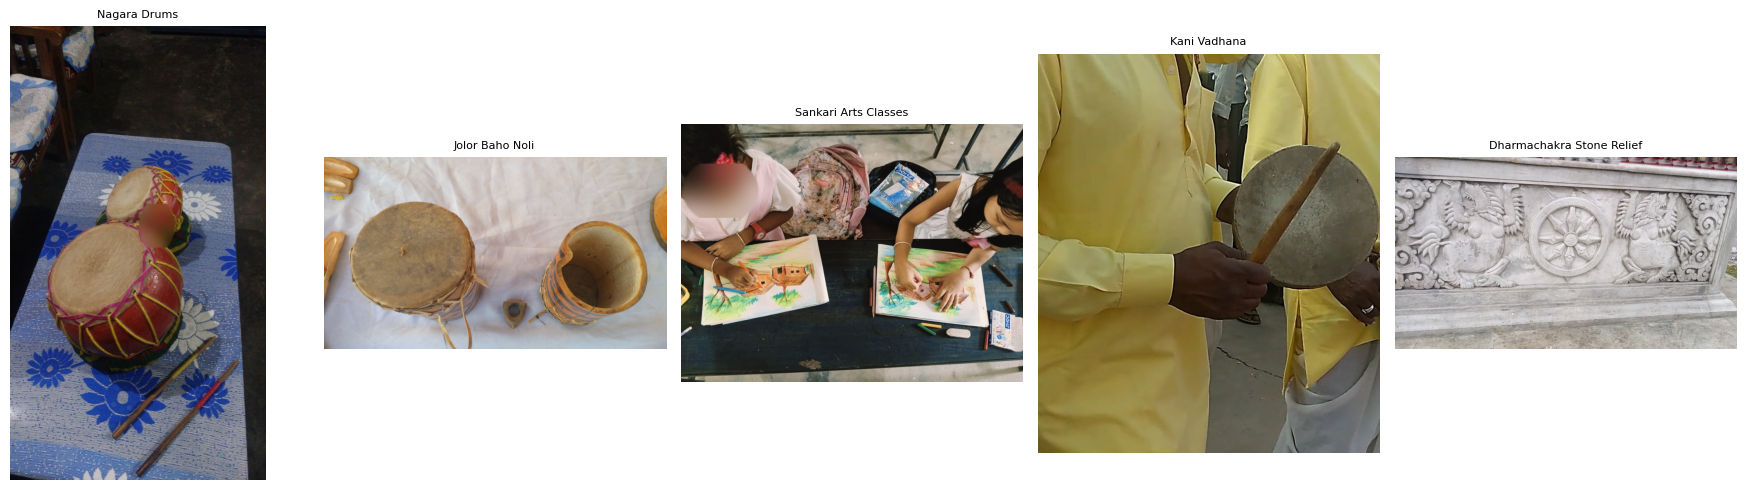

In [15]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

manifest = pd.read_csv("data/subset_manifest.csv")

print("Total images in manifest:", len(manifest))

valid_images = []

for path in manifest["local_path"]:
    try:
        img = Image.open(path)
        img.verify()
        valid_images.append(path)
    except Exception as e:
        print("Invalid image:", path, e)

print("Valid images:", len(valid_images))
print("Invalid images:", len(manifest) - len(valid_images))

# Display first 5 images
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, (_, row) in zip(axes, manifest.head(5).iterrows()):
    img = Image.open(row["local_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(row["name"][:25], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [1]:
!pip install -q transformers torch torchvision

In [2]:
import torch
from transformers import CLIPProcessor, CLIPModel

MODEL_NAME = "openai/clip-vit-base-patch32"

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

model = CLIPModel.from_pretrained(MODEL_NAME)
processor = CLIPProcessor.from_pretrained(MODEL_NAME)

model = model.to(device)
model.eval()

print("CLIP model loaded successfully!")

Using device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (4 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP model loaded successfully!


In [3]:

import torch
import numpy as np
import pandas as pd
from PIL import Image
import os

# Load our 200-image manifest
manifest = pd.read_csv("data/subset_manifest.csv")

all_embeddings = []
batch_size = 16

# Generate embeddings in batches
with torch.no_grad():

    for start in range(0, len(manifest), batch_size):

        batch = manifest.iloc[start:start + batch_size]

        images = [
            Image.open(path).convert("RGB")
            for path in batch["local_path"]
        ]

        inputs = processor(
            images=images,
            return_tensors="pt"
        ).to(device)

        features = model.get_image_features(**inputs)

        # Normalize embeddings for cosine similarity
        features = features / features.norm(
            dim=-1, keepdim=True
        )

        all_embeddings.append(features.cpu().numpy())

        print(
            f"Processed {min(start + batch_size, len(manifest))}"
            f" / {len(manifest)} images"
        )

# Combine all batches
image_embeddings = np.concatenate(all_embeddings, axis=0)

# Save embeddings
os.makedirs("results", exist_ok=True)

np.save("results/image_embeddings.npy", image_embeddings)

print("\nImage embedding generation complete!")
print("Embedding shape:", image_embeddings.shape)
print("Embeddings saved successfully!")


FileNotFoundError: [Errno 2] No such file or directory: 'data/subset_manifest.csv'

In [4]:
import os

print("Current working directory:", os.getcwd())
print("\nFolders in current location:")
print(os.listdir("."))

print("\nSearching for subset_manifest.csv...")

for root, dirs, files in os.walk("/content"):
    if "subset_manifest.csv" in files:
        print("FOUND:", os.path.join(root, "subset_manifest.csv"))


Current working directory: /content

Folders in current location:
['.config', 'sample_data']

Searching for subset_manifest.csv...


In [5]:
!git clone https://github.com/anvisingla09/UCS532-CV-PROJECT.git
%cd /content/UCS532-CV-PROJECT

Cloning into 'UCS532-CV-PROJECT'...
remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 4 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (4/4), done.
/content/UCS532-CV-PROJECT


In [6]:
import os
print("Current folder:", os.getcwd())
print("Project files:", os.listdir("."))

Current folder: /content/UCS532-CV-PROJECT
Project files: ['README.md', '.gitignore', '.git']


In [7]:
!git config --global user.name "anvisingla09"
!git config --global user.email "aanvi1_be24@thapar.edu"

In [8]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [9]:
!pwd
!ls -la

/content/UCS532-CV-PROJECT
total 24
drwxr-xr-x 3 root root 4096 Nov 27 10:47 .
drwxr-xr-x 1 root root 4096 Nov 27 10:47 ..
drwxr-xr-x 8 root root 4096 Nov 27 10:50 .git
-rw-r--r-- 1 root root 4698 Nov 27 10:47 .gitignore
-rw-r--r-- 1 root root   38 Nov 27 10:47 README.md
